# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** Shalmali K &nbsp;&nbsp; **Roll No.:** 1RUA25CSE0432 &nbsp;&nbsp; **Date:** 9/11/26

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

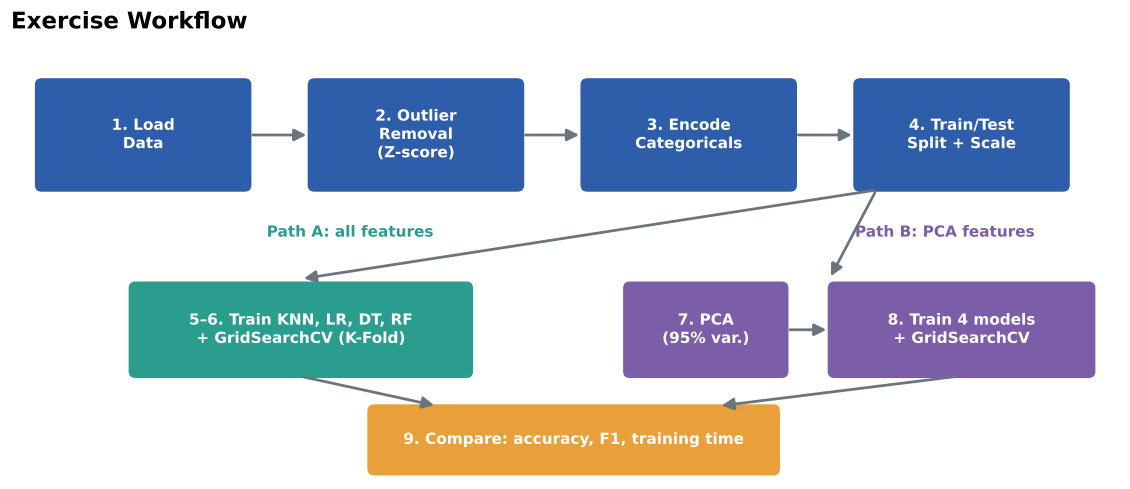

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from scipy.stats import zscore

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [3]:
# Load the Heart Disease dataset

df = pd.read_csv("heart.csv")

# Display first five records
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [4]:
# Display dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nData Types:")
print(df.dtypes)

Dataset Shape: (918, 12)

Column Names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data Types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object


### 1.3 Check for missing values

In [5]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total missing values: 0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

HeartDisease
1    508
0    410
Name: count, dtype: int64

Class percentages:
HeartDisease
1    55.337691
0    44.662309
Name: proportion, dtype: float64


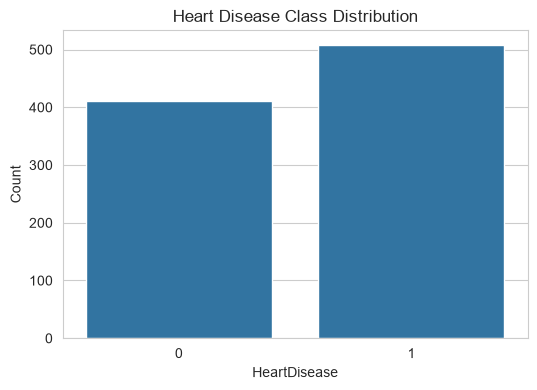

In [6]:
# Check class balance

print(df["HeartDisease"].value_counts())

print("\nClass percentages:")
print(df["HeartDisease"].value_counts(normalize=True) * 100)

# Visualise class balance
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="HeartDisease")
plt.title("Heart Disease Class Distribution")
plt.xlabel("HeartDisease")
plt.ylabel("Count")
plt.show()

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> Observations:

The dataset contains 918 rows and 12 columns. The text-based columns are Sex, ChestPainType, RestingECG, ExerciseAngina, and ST_Slope. There are no missing values in any column, with a total of 0 missing values. The HeartDisease target variable contains 508 positive cases (55.34%) and 410 negative cases (44.66%), indicating a reasonably balanced class distribution. Cholesterol and RestingBP contain some 0 values, which may represent hidden missing values and should be considered during preprocessing.

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.



**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

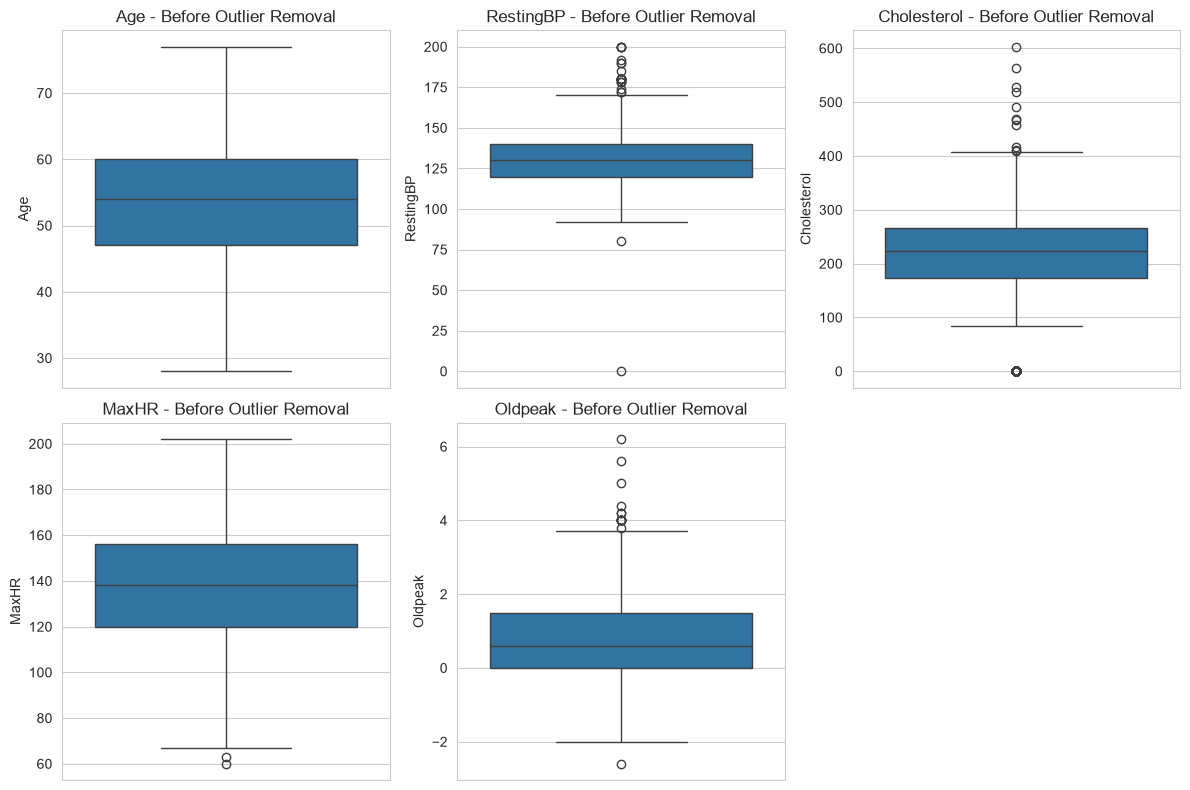

In [7]:
# Numerical features specified in the assignment

numerical_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak"
]

# Boxplots
plt.figure(figsize=(12, 8))

for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[feature])
    plt.title(f"{feature} - Before Outlier Removal")

plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [8]:
# Calculate absolute Z-scores for continuous numerical features

z_scores = df[numerical_features].apply(zscore)

# Display first few Z-score values
z_scores.head()

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
0,-1.433140,0.410909,0.825070,1.382928,-0.832432
1,-0.478484,1.491752,-0.171961,0.754157,0.105664
2,-1.751359,-0.129513,0.770188,-1.525138,-0.832432
3,-0.584556,0.302825,0.139040,-1.132156,0.574711
4,0.051881,0.951331,-0.034755,-0.581981,-0.832432


### 2.3 Identify and count the outlier records

In [9]:
# Identify records having |Z-score| > 3 in any numerical feature

outlier_mask = (z_scores.abs() > 3).any(axis=1)

# Count outlier records
num_outliers = outlier_mask.sum()

print("Number of outlier records:", num_outliers)

# Count outliers contributed by each feature
outliers_by_feature = (z_scores.abs() > 3).sum()

print("\nOutliers by feature:")
print(outliers_by_feature)

# Display outlier records
print("\nOutlier records:")
display(df[outlier_mask])

Number of outlier records: 19

Outliers by feature:
Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64

Outlier records:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
76,32,M,ASY,118,529,0,Normal,130,N,0.0,Flat,1
109,39,M,ATA,190,241,0,Normal,106,N,0.0,Up,0
149,54,M,ASY,130,603,1,Normal,125,Y,1.0,Flat,1
166,50,M,ASY,140,231,0,ST,140,Y,5.0,Flat,1
241,54,M,ASY,200,198,0,Normal,142,Y,2.0,Flat,1
324,46,M,ASY,100,0,1,ST,133,N,-2.6,Flat,1
365,64,F,ASY,200,0,0,Normal,140,Y,1.0,Flat,1
390,51,M,ASY,140,0,0,Normal,60,N,0.0,Flat,1
399,61,M,NAP,200,0,1,ST,70,N,0.0,Flat,1
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


### 2.4 Remove the outliers and display the new shape

In [10]:
# Shape before removal
shape_before = df.shape

# Remove outliers
df_clean = df.loc[~outlier_mask].copy()

# Shape after removal
shape_after = df_clean.shape

print("Shape before outlier removal:", shape_before)
print("Shape after outlier removal:", shape_after)
print("Number of records removed:", shape_before[0] - shape_after[0])

# Update df to the cleaned dataset
df = df_clean

# Display new shape
print("\nUpdated dataset shape:", df.shape)

Shape before outlier removal: (918, 12)
Shape after outlier removal: (899, 12)
Number of records removed: 19

Updated dataset shape: (899, 12)


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> Q2 Answer:

19 records were removed during outlier detection. RestingBP contributed the most outliers, with 8 outliers, followed by Oldpeak with 7 outliers, Cholesterol with 3 outliers, and MaxHR with 1 outlier.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.



| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [11]:
# Identify categorical features

categorical_features = df.select_dtypes(include=["object"]).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nUnique values in each categorical feature:")

for feature in categorical_features:
    print(f"\n{feature}:")
    print(df[feature].unique())

Categorical features:
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Unique values in each categorical feature:

Sex:
<StringArray>
['M', 'F']
Length: 2, dtype: str

ChestPainType:
<StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str

RestingECG:
<StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str

ExerciseAngina:
<StringArray>
['N', 'Y']
Length: 2, dtype: str

ST_Slope:
<StringArray>
['Up', 'Flat', 'Down']
Length: 3, dtype: str


### 3.2 Apply Label Encoding

In [12]:
# Apply Label Encoding to binary categorical features

label_encoder = LabelEncoder()

binary_features = ["Sex", "ExerciseAngina"]

for feature in binary_features:
    df[feature] = label_encoder.fit_transform(df[feature])

print("Label encoding completed.")

print("\nEncoded binary features:")
display(df[binary_features].head())

Label encoding completed.

Encoded binary features:


,Sex,ExerciseAngina
0,1,0
1,0,0
2,1,0
3,0,1
4,1,0


### 3.3 Apply One-Hot Encoding

In [13]:
# Apply One-Hot Encoding to nominal categorical features

nominal_features = [
    "ChestPainType",
    "RestingECG",
    "ST_Slope"
]

df = pd.get_dummies(
    df,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

print("One-Hot Encoding completed.")

print("\nNew dataset shape:", df.shape)

display(df.head())

One-Hot Encoding completed.

New dataset shape: (899, 16)


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


### 3.4 Display the final encoded dataset

In [14]:
# Display final encoded dataset

print("Final encoded dataset:")
display(df.head())

print("\nFinal shape:", df.shape)

print("\nData types:")
print(df.dtypes)

Final encoded dataset:


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1



Final shape: (899, 16)

Data types:
Age                    int64
Sex                    int64
RestingBP              int64
Cholesterol            int64
FastingBS              int64
MaxHR                  int64
ExerciseAngina         int64
Oldpeak              float64
HeartDisease           int64
ChestPainType_ATA      int64
ChestPainType_NAP      int64
ChestPainType_TA       int64
RestingECG_Normal      int64
RestingECG_ST          int64
ST_Slope_Flat          int64
ST_Slope_Up            int64
dtype: object


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> Q3 Answer:

Label encoding was used for binary categorical features, Sex and ExerciseAngina, because they contain only two categories. One-Hot Encoding was used for the nominal categorical features, ChestPainType, RestingECG, and ST_Slope, because they contain multiple categories and do not have an ordinal relationship.

After encoding, the dataset has 16 features.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.



**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [15]:
# Separate features and target

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (899, 15)
Target shape: (899,)

Features:
['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 4.2 Split into training and testing sets

In [16]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set shape: (719, 15)
Testing set shape: (180, 15)

Training target distribution:
HeartDisease
1    393
0    326
Name: count, dtype: int64

Testing target distribution:
HeartDisease
1    99
0    81
Name: count, dtype: int64


### 4.3 Apply feature scaling (fit on training data only)

In [17]:
# Standardize features
# IMPORTANT: Fit scaler only on training data

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

# Convert back to DataFrame for easier viewing
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

display(X_train_scaled_df.head())

Scaled training data shape: (719, 15)
Scaled testing data shape: (180, 15)


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
192,-0.588355,0.530698,-0.124037,0.411677,-0.541448,0.924319,-0.824564,-0.853342,2.024671,-0.524235,-0.229584,0.819813,-0.491728,-1.006978,1.138914
139,-1.107789,0.530698,1.060329,0.430614,-0.541448,-0.267050,1.212761,1.136452,-0.493908,-0.524235,-0.229584,0.819813,-0.491728,0.993070,-0.878030
195,0.866060,-1.884312,1.652513,-0.080702,-0.541448,-0.823022,-0.824564,-0.853342,-0.493908,-0.524235,4.355711,0.819813,-0.491728,-1.006978,1.138914
135,-0.484468,0.530698,-1.012312,0.601053,-0.541448,1.520004,-0.824564,-0.853342,-0.493908,1.907540,-0.229584,0.819813,-0.491728,0.993070,-0.878030
211,-0.380581,-1.884312,0.468146,0.818837,-0.541448,0.130073,1.212761,-0.853342,-0.493908,1.907540,-0.229584,0.819813,-0.491728,0.993070,-0.878030


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> Q4 Answer:

StandardScaler was chosen to scale the numerical features so that they have a similar scale and mean of 0 with standard deviation of 1. This is important for models such as KNN, Logistic Regression, and SVM.

The scaler was fitted only on the training data and then used to transform both the training and testing data. If the scaler were fitted on the entire dataset before splitting, information from the testing set would leak into the training process, causing data leakage and potentially giving overly optimistic model performance.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [18]:
# Helper function for training and evaluation

def evaluate_model(model, X_train, X_test, y_train, y_test):
    
    start_time = time.time()
    
    # Train model
    model.fit(X_train, y_train)
    
    training_time = time.time() - start_time
    
    # Predictions
    y_pred = model.predict(X_test)
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    
    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    
    return {
        "Model": model.__class__.__name__,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Training Time (s)": training_time,
        "Confusion Matrix": cm,
        "Model Object": model
    }

### 5.2 K-Nearest Neighbors

KNN Results
Accuracy : 0.8888888888888888
Precision: 0.883495145631068
Recall   : 0.9191919191919192
F1-score : 0.900990099009901
Training Time: 0.011120319366455078

Confusion Matrix:
[[69 12]
 [ 8 91]]


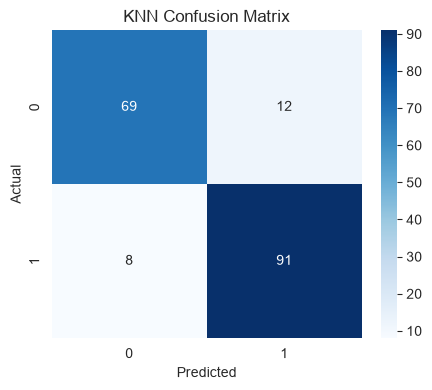

In [19]:
# K-Nearest Neighbors

knn = KNeighborsClassifier()

knn_result = evaluate_model(
    knn,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("KNN Results")
print("Accuracy :", knn_result["Accuracy"])
print("Precision:", knn_result["Precision"])
print("Recall   :", knn_result["Recall"])
print("F1-score :", knn_result["F1"])
print("Training Time:", knn_result["Training Time (s)"])

print("\nConfusion Matrix:")
print(knn_result["Confusion Matrix"])

# Plot confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    knn_result["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 5.3 Logistic Regression

Logistic Regression Results
Accuracy : 0.8722222222222222
Precision: 0.8725490196078431
Recall   : 0.898989898989899
F1-score : 0.8855721393034826
Training Time: 0.030649423599243164

Confusion Matrix:
[[68 13]
 [10 89]]


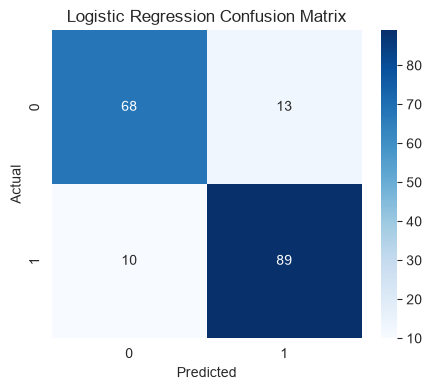

In [20]:
# Logistic Regression

logistic = LogisticRegression(random_state=42)

logistic_result = evaluate_model(
    logistic,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("Logistic Regression Results")
print("Accuracy :", logistic_result["Accuracy"])
print("Precision:", logistic_result["Precision"])
print("Recall   :", logistic_result["Recall"])
print("F1-score :", logistic_result["F1"])
print("Training Time:", logistic_result["Training Time (s)"])

print("\nConfusion Matrix:")
print(logistic_result["Confusion Matrix"])

plt.figure(figsize=(5, 4))
sns.heatmap(
    logistic_result["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 5.4 Decision Tree

Decision Tree Results
Accuracy : 0.8166666666666667
Precision: 0.83
Recall   : 0.8383838383838383
F1-score : 0.8341708542713567
Training Time: 0.014218568801879883

Confusion Matrix:
[[64 17]
 [16 83]]


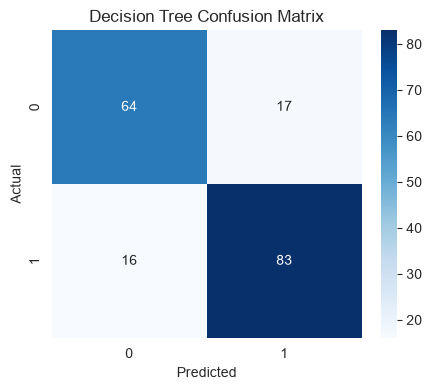

In [21]:
# Decision Tree

decision_tree = DecisionTreeClassifier(random_state=42)

dt_result = evaluate_model(
    decision_tree,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("Decision Tree Results")
print("Accuracy :", dt_result["Accuracy"])
print("Precision:", dt_result["Precision"])
print("Recall   :", dt_result["Recall"])
print("F1-score :", dt_result["F1"])
print("Training Time:", dt_result["Training Time (s)"])

print("\nConfusion Matrix:")
print(dt_result["Confusion Matrix"])

plt.figure(figsize=(5, 4))
sns.heatmap(
    dt_result["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 5.5 Random Forest

Random Forest Results
Accuracy : 0.8722222222222222
Precision: 0.8653846153846154
Recall   : 0.9090909090909091
F1-score : 0.8866995073891626
Training Time: 0.41516804695129395

Confusion Matrix:
[[67 14]
 [ 9 90]]


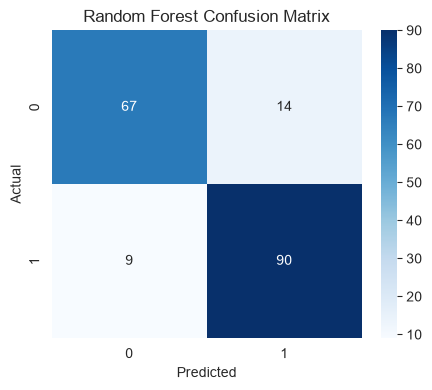

In [22]:
# Random Forest

random_forest = RandomForestClassifier(random_state=42)

rf_result = evaluate_model(
    random_forest,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("Random Forest Results")
print("Accuracy :", rf_result["Accuracy"])
print("Precision:", rf_result["Precision"])
print("Recall   :", rf_result["Recall"])
print("F1-score :", rf_result["F1"])
print("Training Time:", rf_result["Training Time (s)"])

print("\nConfusion Matrix:")
print(rf_result["Confusion Matrix"])

plt.figure(figsize=(5, 4))
sns.heatmap(
    rf_result["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 5.6 Comparison table and bar chart of all four models

Comparison of models before tuning:


,Model,Accuracy,Precision,Recall,F1,Training Time (s)
0,KNN,0.888889,0.883495,0.919192,0.900990,0.011120
1,Logistic Regression,0.872222,0.872549,0.898990,0.885572,0.030649
2,Decision Tree,0.816667,0.830000,0.838384,0.834171,0.014219
3,Random Forest,0.872222,0.865385,0.909091,0.886700,0.415168


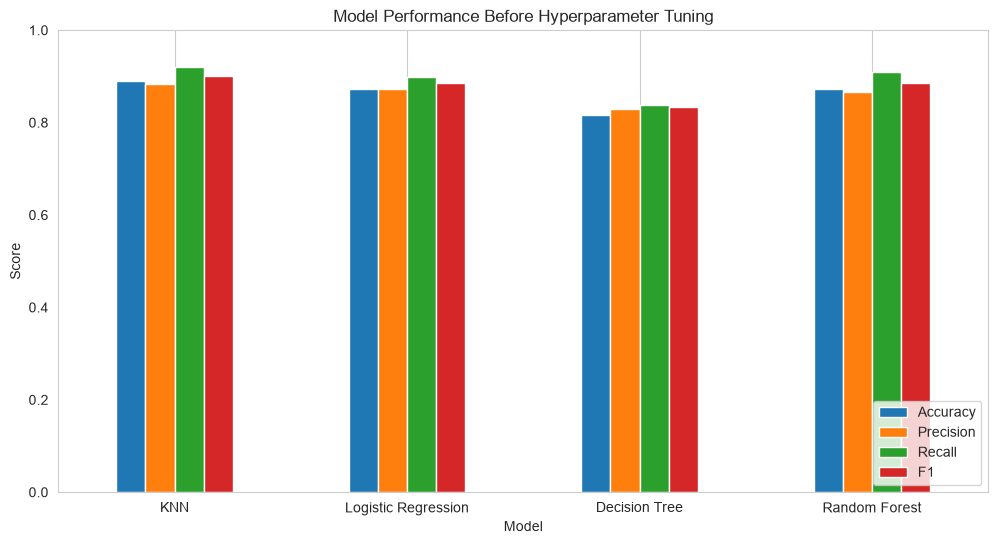

In [23]:
# Create comparison table for all four models

before_pca_results = pd.DataFrame([
    {
        "Model": "KNN",
        "Accuracy": knn_result["Accuracy"],
        "Precision": knn_result["Precision"],
        "Recall": knn_result["Recall"],
        "F1": knn_result["F1"],
        "Training Time (s)": knn_result["Training Time (s)"]
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_result["Accuracy"],
        "Precision": logistic_result["Precision"],
        "Recall": logistic_result["Recall"],
        "F1": logistic_result["F1"],
        "Training Time (s)": logistic_result["Training Time (s)"]
    },
    {
        "Model": "Decision Tree",
        "Accuracy": dt_result["Accuracy"],
        "Precision": dt_result["Precision"],
        "Recall": dt_result["Recall"],
        "F1": dt_result["F1"],
        "Training Time (s)": dt_result["Training Time (s)"]
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_result["Accuracy"],
        "Precision": rf_result["Precision"],
        "Recall": rf_result["Recall"],
        "F1": rf_result["F1"],
        "Training Time (s)": rf_result["Training Time (s)"]
    }
])

print("Comparison of models before tuning:")
display(before_pca_results)

# Bar chart
metrics = ["Accuracy", "Precision", "Recall", "F1"]

before_pca_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Before Hyperparameter Tuning")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> Q5 Answer:

KNN achieved the highest test accuracy of 88.89%. However, in a medical diagnosis setting, accuracy should not be the only important metric. Recall should be prioritised because it measures the ability to correctly identify patients who actually have heart disease. A high recall helps reduce false negatives, which is important because missing a disease case can have serious consequences.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.


**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [24]:
# Stratified K-Fold cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Hyperparameter grids

knn_param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

logistic_param_grid = [
    {
        "C": [0.01, 0.1, 1, 10, 100],
        "penalty": ["l2"],
        "solver": ["lbfgs"]
    },
    {
        "C": [0.01, 0.1, 1, 10, 100],
        "penalty": ["l1"],
        "solver": ["liblinear"]
    }
]

dt_param_grid = {
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"]
}

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"]
}

print("Cross-validation strategy and parameter grids created.")

Cross-validation strategy and parameter grids created.


### 6.2 Tune KNN

In [25]:
# Tune KNN using GridSearchCV

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

knn_grid.fit(X_train_scaled, y_train)

knn_tuning_time = time.time() - start_time

print("Best KNN parameters:")
print(knn_grid.best_params_)

print("\nBest CV Accuracy:", knn_grid.best_score_)
print("Tuning Time:", knn_tuning_time)

# Evaluate best KNN model on test set
knn_tuned_result = evaluate_model(
    knn_grid.best_estimator_,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("\nTest Accuracy:", knn_tuned_result["Accuracy"])
print("Test Precision:", knn_tuned_result["Precision"])
print("Test Recall:", knn_tuned_result["Recall"])
print("Test F1:", knn_tuned_result["F1"])

Best KNN parameters:
{'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}

Best CV Accuracy: 0.8803418803418804
Tuning Time: 18.073877334594727

Test Accuracy: 0.8944444444444445
Test Precision: 0.8921568627450981
Test Recall: 0.9191919191919192
Test F1: 0.9054726368159204


### 6.3 Tune Logistic Regression

In [26]:
# Tune Logistic Regression

logistic_grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

logistic_grid.fit(X_train_scaled, y_train)

logistic_tuning_time = time.time() - start_time

print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)

print("\nBest CV Accuracy:", logistic_grid.best_score_)
print("Tuning Time:", logistic_tuning_time)

# Evaluate best model
logistic_tuned_result = evaluate_model(
    logistic_grid.best_estimator_,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("\nTest Accuracy:", logistic_tuned_result["Accuracy"])
print("Test Precision:", logistic_tuned_result["Precision"])
print("Test Recall:", logistic_tuned_result["Recall"])
print("Test F1:", logistic_tuned_result["F1"])

Best Logistic Regression parameters:
{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}

Best CV Accuracy: 0.8678321678321679
Tuning Time: 0.33476758003234863

Test Accuracy: 0.8777777777777778
Test Precision: 0.8737864077669902
Test Recall: 0.9090909090909091
Test F1: 0.8910891089108911


### 6.4 Tune Decision Tree

In [27]:
# Tune Decision Tree

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

dt_grid.fit(X_train_scaled, y_train)

dt_tuning_time = time.time() - start_time

print("Best Decision Tree parameters:")
print(dt_grid.best_params_)

print("\nBest CV Accuracy:", dt_grid.best_score_)
print("Tuning Time:", dt_tuning_time)

# Evaluate best model
dt_tuned_result = evaluate_model(
    dt_grid.best_estimator_,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("\nTest Accuracy:", dt_tuned_result["Accuracy"])
print("Test Precision:", dt_tuned_result["Precision"])
print("Test Recall:", dt_tuned_result["Recall"])
print("Test F1:", dt_tuned_result["F1"])

Best Decision Tree parameters:
{'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best CV Accuracy: 0.8344308469308469
Tuning Time: 2.238308906555176

Test Accuracy: 0.8222222222222222
Test Precision: 0.8764044943820225
Test Recall: 0.7878787878787878
Test F1: 0.8297872340425532


### 6.5 Tune Random Forest

In [28]:
# Tune Random Forest

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

rf_grid.fit(X_train_scaled, y_train)

rf_tuning_time = time.time() - start_time

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("\nBest CV Accuracy:", rf_grid.best_score_)
print("Tuning Time:", rf_tuning_time)

# Evaluate best model
rf_tuned_result = evaluate_model(
    rf_grid.best_estimator_,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

print("\nTest Accuracy:", rf_tuned_result["Accuracy"])
print("Test Precision:", rf_tuned_result["Precision"])
print("Test Recall:", rf_tuned_result["Recall"])
print("Test F1:", rf_tuned_result["F1"])

Best Random Forest parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}

Best CV Accuracy: 0.8747766122766123
Tuning Time: 32.892842054367065

Test Accuracy: 0.8666666666666667
Test Precision: 0.8504672897196262
Test Recall: 0.9191919191919192
Test F1: 0.883495145631068


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

Tuned Model Comparison:


,Model,Accuracy,Precision,Recall,F1,Best CV Score,Training Time (s)
0,KNN,0.894444,0.892157,0.919192,0.905473,0.880342,0.005364
1,Logistic Regression,0.877778,0.873786,0.909091,0.891089,0.867832,0.012080
2,Decision Tree,0.822222,0.876404,0.787879,0.829787,0.834431,0.006903
3,Random Forest,0.866667,0.850467,0.919192,0.883495,0.874777,0.410584


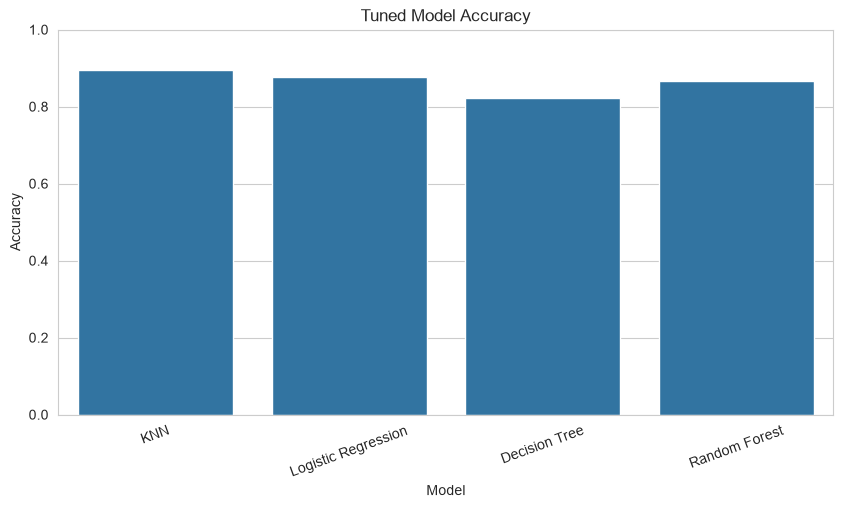

In [29]:
# Create comparison table for tuned models

tuned_results = pd.DataFrame([
    {
        "Model": "KNN",
        "Accuracy": knn_tuned_result["Accuracy"],
        "Precision": knn_tuned_result["Precision"],
        "Recall": knn_tuned_result["Recall"],
        "F1": knn_tuned_result["F1"],
        "Best CV Score": knn_grid.best_score_,
        "Training Time (s)": knn_tuned_result["Training Time (s)"]
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_tuned_result["Accuracy"],
        "Precision": logistic_tuned_result["Precision"],
        "Recall": logistic_tuned_result["Recall"],
        "F1": logistic_tuned_result["F1"],
        "Best CV Score": logistic_grid.best_score_,
        "Training Time (s)": logistic_tuned_result["Training Time (s)"]
    },
    {
        "Model": "Decision Tree",
        "Accuracy": dt_tuned_result["Accuracy"],
        "Precision": dt_tuned_result["Precision"],
        "Recall": dt_tuned_result["Recall"],
        "F1": dt_tuned_result["F1"],
        "Best CV Score": dt_grid.best_score_,
        "Training Time (s)": dt_tuned_result["Training Time (s)"]
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_tuned_result["Accuracy"],
        "Precision": rf_tuned_result["Precision"],
        "Recall": rf_tuned_result["Recall"],
        "F1": rf_tuned_result["F1"],
        "Best CV Score": rf_grid.best_score_,
        "Training Time (s)": rf_tuned_result["Training Time (s)"]
    }
])

print("Tuned Model Comparison:")
display(tuned_results)

# Plot test accuracy
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tuned_results,
    x="Model",
    y="Accuracy"
)

plt.title("Tuned Model Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> Q6 Answer:

Hyperparameter tuning did not improve every model. KNN, Logistic Regression, and Decision Tree improved their test accuracy from 88.89% to 89.44%, 87.22% to 87.78%, and 81.67% to 82.22%, respectively. Random Forest decreased from 87.22% to 86.67%.

KNN, Logistic Regression, and Decision Tree benefited equally, with an improvement of about 0.56 percentage points each. KNN achieved the highest tuned test accuracy of 89.44%.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.



**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

Explained variance ratio:
[0.22699266 0.11292647 0.09386112 0.08201416 0.07790533 0.06971947
 0.06211162 0.05553708 0.05205163 0.04343667 0.0394805  0.02847239
 0.02752416 0.02146538 0.00650134]


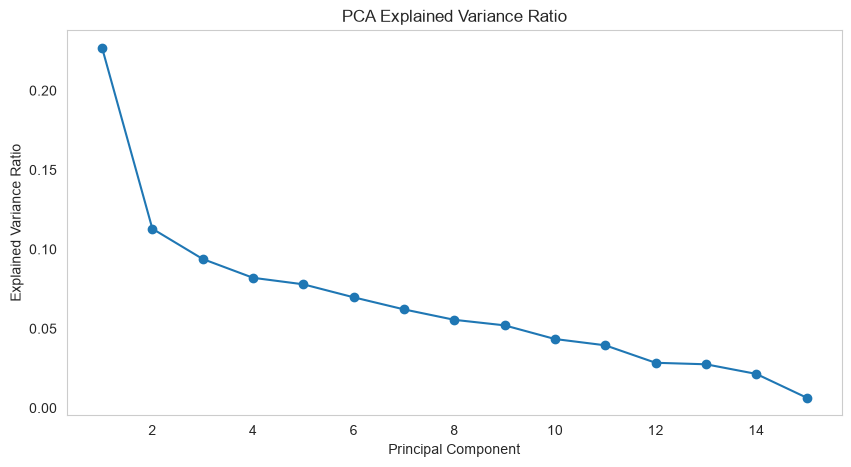

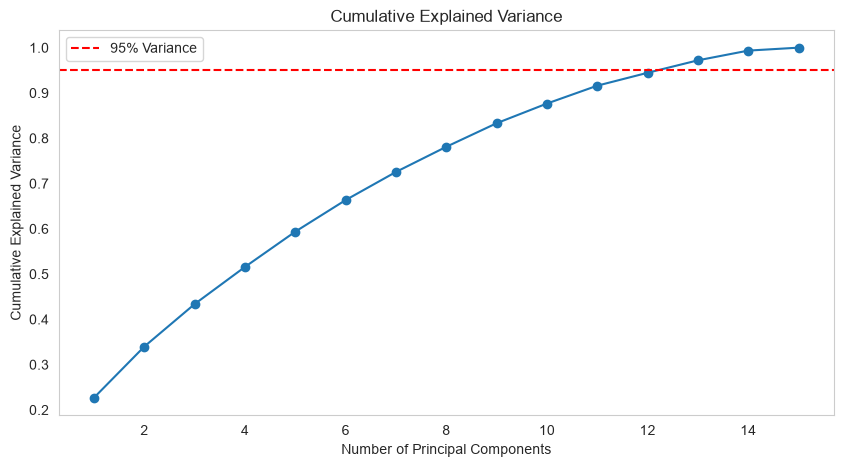

In [30]:
# Fit PCA on scaled training data only

pca_full = PCA()

pca_full.fit(X_train_scaled)

# Explained variance ratio
explained_variance = pca_full.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

print("Explained variance ratio:")
print(explained_variance)

# Plot explained variance
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.title("PCA Explained Variance Ratio")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid()
plt.show()

# Plot cumulative explained variance
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% Variance"
)

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid()
plt.show()

### 7.2 Determine the number of components for 95% variance

In [31]:
# Determine number of components required for 95% variance

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of components needed for 95% variance:",
      n_components_95)

print(
    "Variance retained:",
    cumulative_variance[n_components_95 - 1] * 100,
    "%"
)

print(
    "Original number of features:",
    X_train.shape[1]
)

Number of components needed for 95% variance: 13
Variance retained: 97.2033287551653 %
Original number of features: 15


### 7.3 Transform the training and testing sets

In [32]:
# Create PCA model retaining 95% variance

pca = PCA(n_components=0.95)

# Fit only on training data
X_train_pca = pca.fit_transform(X_train_scaled)

# Transform test data
X_test_pca = pca.transform(X_test_scaled)

print("Original training shape:", X_train_scaled.shape)
print("PCA training shape:", X_train_pca.shape)

print("\nOriginal testing shape:", X_test_scaled.shape)
print("PCA testing shape:", X_test_pca.shape)

print(
    "\nNumber of PCA components:",
    pca.n_components_
)

# Percentage reduction in features
original_features = X_train.shape[1]
reduced_features = X_train_pca.shape[1]

reduction_percentage = (
    (original_features - reduced_features)
    / original_features
) * 100

print(
    "Feature reduction:",
    round(reduction_percentage, 2),
    "%"
)

Original training shape: (719, 15)
PCA training shape: (719, 13)

Original testing shape: (180, 15)
PCA testing shape: (180, 13)

Number of PCA components: 13
Feature reduction: 13.33 %


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

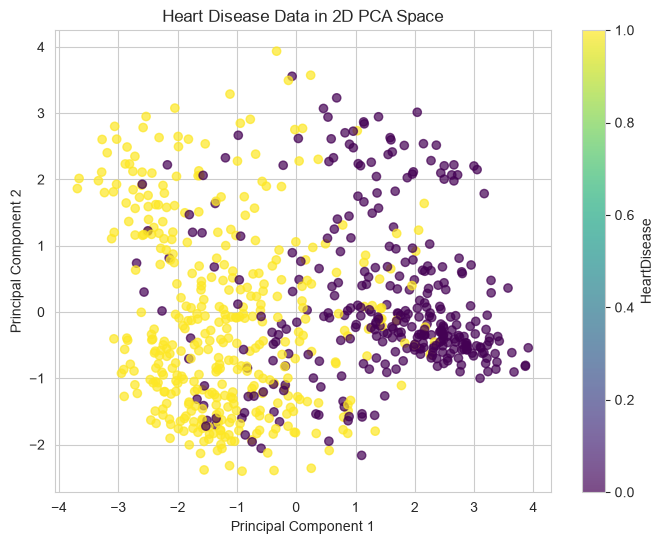

In [33]:
# Visualise first two principal components

pca_2d = PCA(n_components=2)

X_train_pca_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X_train_pca_2d[:, 0],
    X_train_pca_2d[:, 1],
    c=y_train,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Heart Disease Data in 2D PCA Space")

plt.colorbar(
    scatter,
    label="HeartDisease"
)

plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> Q7 Answer:

13 principal components are needed to retain 95% of the variance. The PCA retained 97.20% of the variance. The number of features was reduced from 15 to 13, resulting in a feature reduction of 13.33%.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [34]:
# KNN after PCA

knn_pca_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

knn_pca_grid.fit(X_train_pca, y_train)

knn_pca_tuning_time = time.time() - start_time

knn_pca_result = evaluate_model(
    knn_pca_grid.best_estimator_,
    X_train_pca,
    X_test_pca,
    y_train,
    y_test
)

print("KNN after PCA")
print("Best Parameters:", knn_pca_grid.best_params_)
print("Best CV Score:", knn_pca_grid.best_score_)
print("Accuracy:", knn_pca_result["Accuracy"])
print("Precision:", knn_pca_result["Precision"])
print("Recall:", knn_pca_result["Recall"])
print("F1-score:", knn_pca_result["F1"])
print("Training Time:", knn_pca_result["Training Time (s)"])

KNN after PCA
Best Parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best CV Score: 0.872008547008547
Accuracy: 0.9111111111111111
Precision: 0.9029126213592233
Recall: 0.9393939393939394
F1-score: 0.9207920792079208
Training Time: 0.0035283565521240234


### 8.2 Logistic Regression after PCA

In [35]:
# Logistic Regression after PCA

logistic_pca_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

logistic_pca_grid.fit(X_train_pca, y_train)

logistic_pca_tuning_time = time.time() - start_time

logistic_pca_result = evaluate_model(
    logistic_pca_grid.best_estimator_,
    X_train_pca,
    X_test_pca,
    y_train,
    y_test
)

print("Logistic Regression after PCA")
print("Best Parameters:", logistic_pca_grid.best_params_)
print("Best CV Score:", logistic_pca_grid.best_score_)
print("Accuracy:", logistic_pca_result["Accuracy"])
print("Precision:", logistic_pca_result["Precision"])
print("Recall:", logistic_pca_result["Recall"])
print("F1-score:", logistic_pca_result["F1"])
print("Training Time:", logistic_pca_result["Training Time (s)"])

Logistic Regression after PCA
Best Parameters: {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV Score: 0.8650641025641024
Accuracy: 0.8722222222222222
Precision: 0.8725490196078431
Recall: 0.898989898989899
F1-score: 0.8855721393034826
Training Time: 0.004555940628051758


### 8.3 Decision Tree after PCA

In [36]:
# Decision Tree after PCA

dt_pca_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

dt_pca_grid.fit(X_train_pca, y_train)

dt_pca_tuning_time = time.time() - start_time

dt_pca_result = evaluate_model(
    dt_pca_grid.best_estimator_,
    X_train_pca,
    X_test_pca,
    y_train,
    y_test
)

print("Decision Tree after PCA")
print("Best Parameters:", dt_pca_grid.best_params_)
print("Best CV Score:", dt_pca_grid.best_score_)
print("Accuracy:", dt_pca_result["Accuracy"])
print("Precision:", dt_pca_result["Precision"])
print("Recall:", dt_pca_result["Recall"])
print("F1-score:", dt_pca_result["F1"])
print("Training Time:", dt_pca_result["Training Time (s)"])

Decision Tree after PCA
Best Parameters: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Score: 0.8344599844599845
Accuracy: 0.8722222222222222
Precision: 0.88
Recall: 0.8888888888888888
F1-score: 0.8844221105527639
Training Time: 0.011815547943115234


### 8.4 Random Forest after PCA

In [37]:
# Random Forest after PCA

rf_pca_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

start_time = time.time()

rf_pca_grid.fit(X_train_pca, y_train)

rf_pca_tuning_time = time.time() - start_time

rf_pca_result = evaluate_model(
    rf_pca_grid.best_estimator_,
    X_train_pca,
    X_test_pca,
    y_train,
    y_test
)

print("Random Forest after PCA")
print("Best Parameters:", rf_pca_grid.best_params_)
print("Best CV Score:", rf_pca_grid.best_score_)
print("Accuracy:", rf_pca_result["Accuracy"])
print("Precision:", rf_pca_result["Precision"])
print("Recall:", rf_pca_result["Recall"])
print("F1-score:", rf_pca_result["F1"])
print("Training Time:", rf_pca_result["Training Time (s)"])

Random Forest after PCA
Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Best CV Score: 0.8692307692307691
Accuracy: 0.8944444444444445
Precision: 0.8846153846153846
Recall: 0.9292929292929293
F1-score: 0.9064039408866995
Training Time: 0.7901058197021484


### 8.5 Comparison table of all four models after PCA

Model Comparison After PCA:


,Model,Accuracy,Precision,Recall,F1,Best CV Score,Training Time (s)
0,KNN,0.911111,0.902913,0.939394,0.920792,0.872009,0.003528
1,Logistic Regression,0.872222,0.872549,0.898990,0.885572,0.865064,0.004556
2,Decision Tree,0.872222,0.880000,0.888889,0.884422,0.834460,0.011816
3,Random Forest,0.894444,0.884615,0.929293,0.906404,0.869231,0.790106


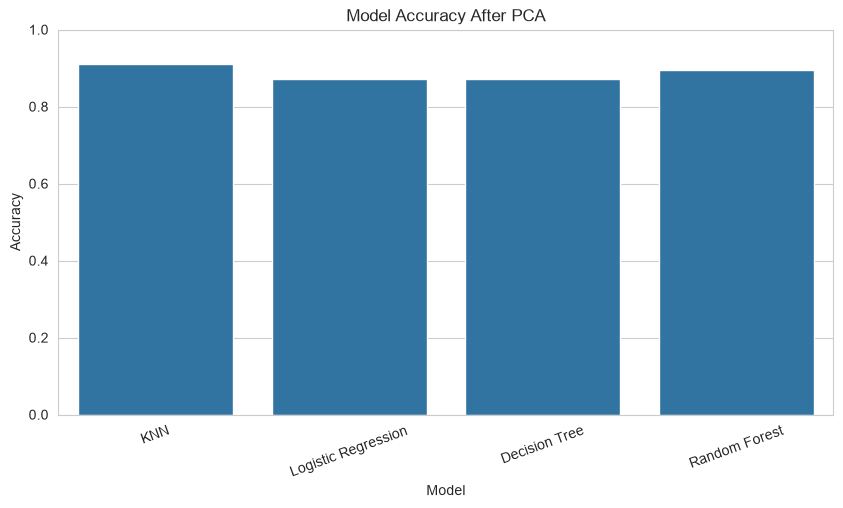

In [38]:
# Comparison table after PCA

after_pca_results = pd.DataFrame([
    {
        "Model": "KNN",
        "Accuracy": knn_pca_result["Accuracy"],
        "Precision": knn_pca_result["Precision"],
        "Recall": knn_pca_result["Recall"],
        "F1": knn_pca_result["F1"],
        "Best CV Score": knn_pca_grid.best_score_,
        "Training Time (s)": knn_pca_result["Training Time (s)"]
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_pca_result["Accuracy"],
        "Precision": logistic_pca_result["Precision"],
        "Recall": logistic_pca_result["Recall"],
        "F1": logistic_pca_result["F1"],
        "Best CV Score": logistic_pca_grid.best_score_,
        "Training Time (s)": logistic_pca_result["Training Time (s)"]
    },
    {
        "Model": "Decision Tree",
        "Accuracy": dt_pca_result["Accuracy"],
        "Precision": dt_pca_result["Precision"],
        "Recall": dt_pca_result["Recall"],
        "F1": dt_pca_result["F1"],
        "Best CV Score": dt_pca_grid.best_score_,
        "Training Time (s)": dt_pca_result["Training Time (s)"]
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_pca_result["Accuracy"],
        "Precision": rf_pca_result["Precision"],
        "Recall": rf_pca_result["Recall"],
        "F1": rf_pca_result["F1"],
        "Best CV Score": rf_pca_grid.best_score_,
        "Training Time (s)": rf_pca_result["Training Time (s)"]
    }
])

print("Model Comparison After PCA:")
display(after_pca_results)

# Accuracy comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=after_pca_results,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy After PCA")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> Q8 Answer:

KNN performed the best after PCA, achieving the highest test accuracy of 91.11%, with a recall of 93.94% and an F1-score of 92.08%. Yes, it is the same model that performed best before PCA, as KNN also had the highest accuracy before PCA at 89.44%.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [39]:
# Create consolidated Before PCA vs After PCA comparison

comparison_df = pd.DataFrame({
    "Model": [
        "KNN",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    
    "Accuracy (Before PCA)": [
        knn_tuned_result["Accuracy"],
        logistic_tuned_result["Accuracy"],
        dt_tuned_result["Accuracy"],
        rf_tuned_result["Accuracy"]
    ],
    
    "Accuracy (After PCA)": [
        knn_pca_result["Accuracy"],
        logistic_pca_result["Accuracy"],
        dt_pca_result["Accuracy"],
        rf_pca_result["Accuracy"]
    ],
    
    "F1 (Before PCA)": [
        knn_tuned_result["F1"],
        logistic_tuned_result["F1"],
        dt_tuned_result["F1"],
        rf_tuned_result["F1"]
    ],
    
    "F1 (After PCA)": [
        knn_pca_result["F1"],
        logistic_pca_result["F1"],
        dt_pca_result["F1"],
        rf_pca_result["F1"]
    ],
    
    "Training Time Before (s)": [
        knn_tuned_result["Training Time (s)"],
        logistic_tuned_result["Training Time (s)"],
        dt_tuned_result["Training Time (s)"],
        rf_tuned_result["Training Time (s)"]
    ],
    
    "Training Time After (s)": [
        knn_pca_result["Training Time (s)"],
        logistic_pca_result["Training Time (s)"],
        dt_pca_result["Training Time (s)"],
        rf_pca_result["Training Time (s)"]
    ],
    
    "No. of Features": [
        X_train_pca.shape[1],
        X_train_pca.shape[1],
        X_train_pca.shape[1],
        X_train_pca.shape[1]
    ]
})

display(comparison_df)

print("\nOriginal number of features:", X_train.shape[1])
print("Number of PCA features:", X_train_pca.shape[1])

,Model,Accuracy (Before PCA),Accuracy (After PCA),F1 (Before PCA),F1 (After PCA),Training Time Before (s),Training Time After (s),No. of Features
0,KNN,0.894444,0.911111,0.905473,0.920792,0.005364,0.003528,13
1,Logistic Regression,0.877778,0.872222,0.891089,0.885572,0.012080,0.004556,13
2,Decision Tree,0.822222,0.872222,0.829787,0.884422,0.006903,0.011816,13
3,Random Forest,0.866667,0.894444,0.883495,0.906404,0.410584,0.790106,13



Original number of features: 15
Number of PCA features: 13


### 9.2 Visualise the before vs after PCA comparison

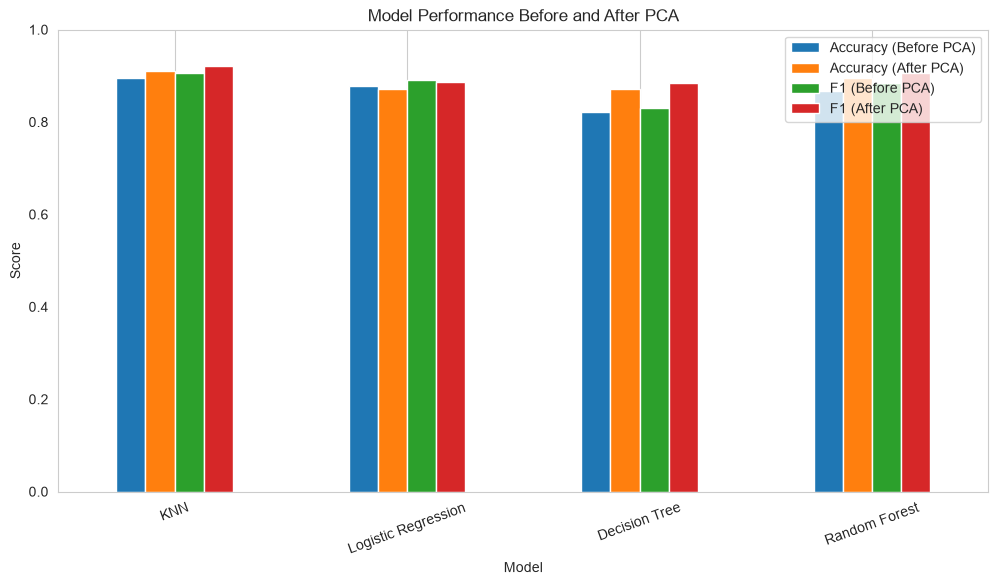

In [40]:
# Grouped bar chart for Accuracy and F1 before vs after PCA

plot_data = comparison_df[
    [
        "Model",
        "Accuracy (Before PCA)",
        "Accuracy (After PCA)",
        "F1 (Before PCA)",
        "F1 (After PCA)"
    ]
]

plot_data = plot_data.set_index("Model")

plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Before and After PCA")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xlabel("Model")
plt.xticks(rotation=20)
plt.legend()
plt.grid(axis="y")
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> Q9a Answer:

After applying PCA, KNN, Decision Tree, and Random Forest improved their accuracy, while Logistic Regression declined slightly. KNN improved from 89.44% to 91.11%, Decision Tree from 82.22% to 87.22%, and Random Forest from 86.67% to 89.44%. Logistic Regression decreased from 87.78% to 87.22%. Overall, PCA improved the performance of most models.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> Q9b Answer:

PCA reduced the number of features from 15 to 13, resulting in a 13.33% reduction in dimensionality. It also reduced the training time for KNN and Logistic Regression. However, the training time of Decision Tree and Random Forest increased after PCA. Therefore, PCA can improve computational efficiency, but the effect depends on the model and dataset.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> Q9c Answer:

Dimensionality reduction improved classification performance for most models in this dataset. KNN, Decision Tree, and Random Forest showed improved accuracy and F1-score after PCA, while Logistic Regression showed a slight decrease. The improvement may be because PCA removes redundant information and reduces the feature space. KNN benefited significantly because it is distance-based. However, PCA can reduce interpretability because the new principal components are combinations of the original features.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> Q9d Answer:

PCA provides a trade-off between predictive accuracy, computational cost, and reduced feature dimensionality. Reducing the number of features can lower computational requirements and remove redundant information, but it may also lose some information important for prediction. PCA is preferred when a dataset has many correlated or high-dimensional features, when computational efficiency is important, or when visualization and noise reduction are required. It is less suitable when the interpretability of the original features is very important.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.